<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Summarise the characteristics of the datasets/ROIs in the collection.
> - **Manuscript panels:** Fig. 1A
> - **Inputs:** per-ROI `rois/<dataset>/metadata.csv` (concatenated here)
> - **Outputs:** Dataset overview plots
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# Aim of the notebook

Visualize the main metadata info, related with Figure 1A

# ROI_processing

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns


from troutpy_reproducibility.batch_running import *

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [54]:
import os
import pandas as pd

# Define the root directory
root_dir = "/media/sergio/Meninges/troutpy/rois"
saving_path='/media/sergio/Meninges/troutpy/figures'


# Initialize an empty list to hold individual metadata DataFrames
metadata_list = []

# List only first-level subdirectories
subfolders = [f.path for f in os.scandir(root_dir) if f.is_dir()]

for subfolder in subfolders:
    metadata_path = os.path.join(subfolder, "metadata.csv")
    if os.path.isfile(metadata_path):
        try:
            df = pd.read_csv(metadata_path)
            df['tag']=subfolder.split('/')[-1]
            # Add subfolder name as a column
            metadata_list.append(df)
        except Exception as e:
            print(f"Failed to read {metadata_path}: {e}")

# Combine all metadata files into a single DataFrame
if metadata_list:
    combined_metadata = pd.concat(metadata_list, ignore_index=True)
    print("Combined metadata shape:", combined_metadata.shape)
else:
    print("No metadata.csv files found.")

Combined metadata shape: (15, 15)


In [56]:
dataset_order.reverse()

In [57]:
combined_metadata.index = combined_metadata["tag"]
dataset_order=['cosmx_hgsoc', 'cosmx_melanoma', 'cosmx_mousebrain', 'cosmx_stomach',
       'merscope_hsbrain', 'merscope_hsuterine',
        'xenium_hsprostate', 'xenium_hsskin_5k',
       'xenium_mscolon_5k', 'xenium_msbrain_5k','xenium_msbrain_300','xenium_hsputamen','xenium_hsheart','xenium_hsfemur']
dataset_order.reverse()
combined_metadata=combined_metadata.loc[dataset_order,:]

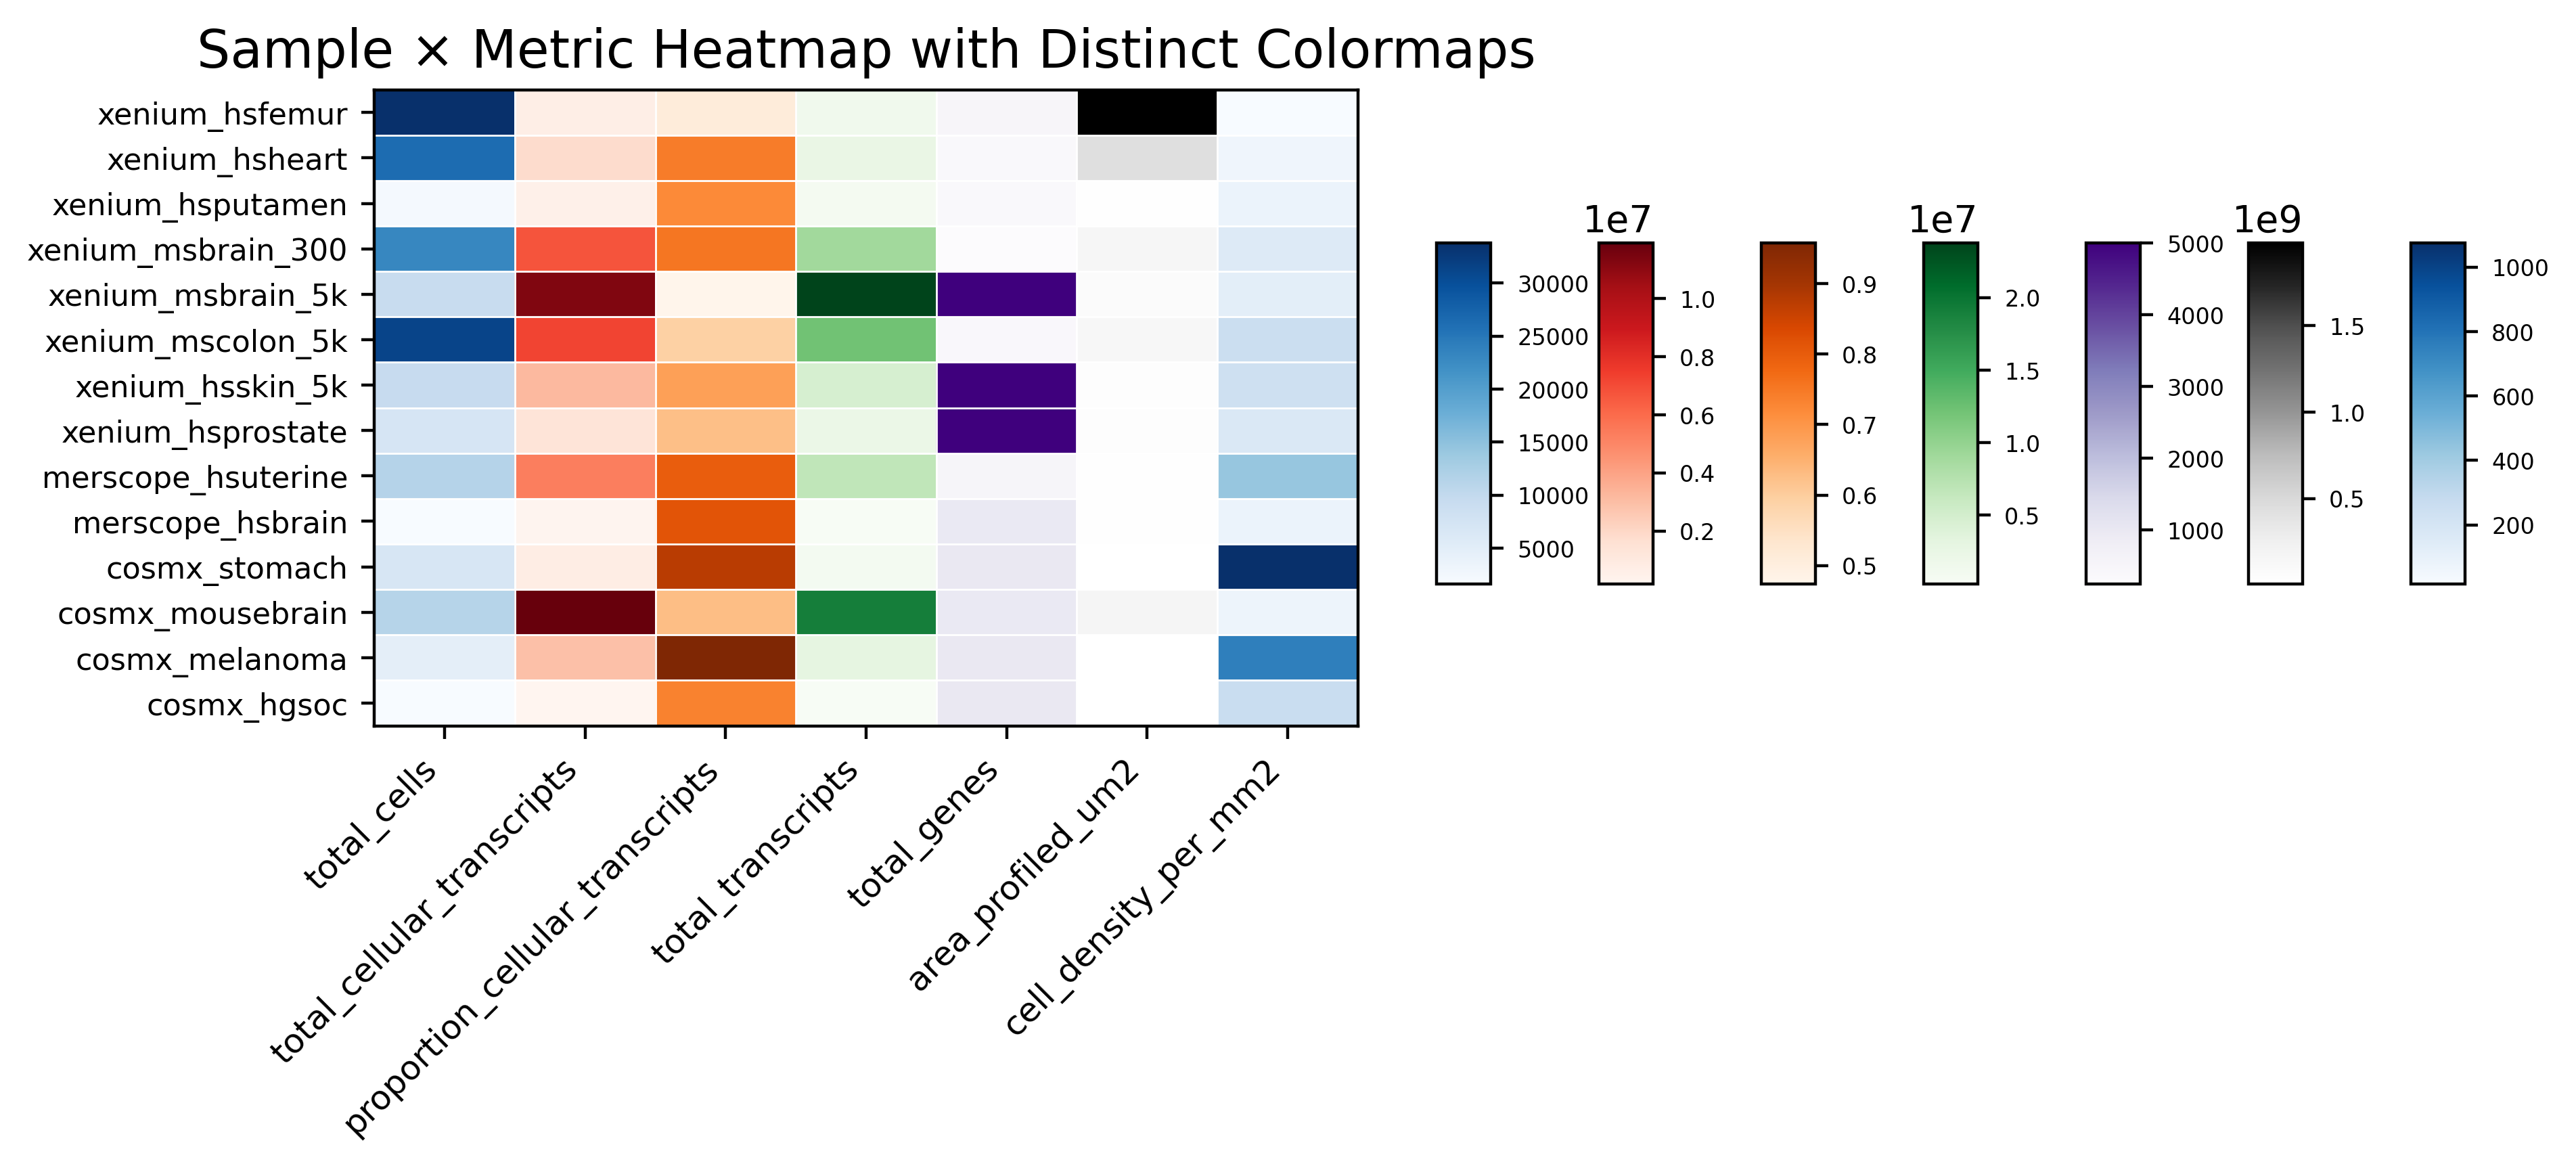

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from sklearn.preprocessing import MinMaxScaler

# Load your combined metadata CSV (update the path as needed)
# combined_metadata = pd.read_csv('/media/sergio/Meninges/troutpy/rois/combined_metadata.csv', index_col=0)

# Metrics to include as columns
metrics = [
    "total_cells",
    "total_cellular_transcripts",
    "proportion_cellular_transcripts",
    "total_transcripts",
    "total_genes",
    "area_profiled_um2",
    "cell_density_per_mm2",
]

# Extract data matrix and sample labels
data = combined_metadata[metrics].values
samples = combined_metadata.index.tolist()
n_samples, n_metrics = data.shape

# Normalize each column independently to [0, 1]
scaler = MinMaxScaler()
norm_data = scaler.fit_transform(data)

# Define a distinct colormap for each metric
colormaps = [cm.Blues, cm.Reds, cm.Oranges, cm.Greens, cm.Purples, cm.Greys, cm.Blues]

# Build an RGB image array: shape = (n_samples, n_metrics, 3)
rgb_image = np.zeros((n_samples, n_metrics, 3))
for j, cmap in enumerate(colormaps):
    rgba = cmap(norm_data[:, j])
    rgb_image[:, j, :] = rgba[:, :3]  # drop alpha channel

# Plot the combined heatmap
fig, ax = plt.subplots(figsize=(5, max(4, n_samples * 0.3)), constrained_layout=True, dpi=400)
ax.imshow(rgb_image, aspect="auto")

# Set axis ticks and labels
ax.set_xticks(np.arange(n_metrics))
ax.set_xticklabels(metrics, rotation=45, ha="right", fontsize=9)
ax.set_yticks(np.arange(n_samples))
ax.set_yticklabels(samples, fontsize=8)

# Add thin white grid lines for readability
ax.set_xticks(np.arange(-0.5, n_metrics, 1), minor=True)
ax.set_yticks(np.arange(-0.5, n_samples, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=0.5)
ax.tick_params(which="minor", length=0)

# Add a vertical colorbar for each metric
for j, cmap in enumerate(colormaps):
    # Create a ScalarMappable for this metric's true range
    norm = plt.Normalize(vmin=data[:, j].min(), vmax=data[:, j].max())
    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    # Position each small cbar to the right of the j-th column
    left = 1.05 + j * 0.12
    cbar_ax = fig.add_axes([left, 0.5, 0.04, 0.3])
    cbar = plt.colorbar(sm, cax=cbar_ax)
    cbar.ax.tick_params(labelsize=6)

ax.set_title("Sample × Metric Heatmap with Distinct Colormaps", fontsize=14)
plt.show()

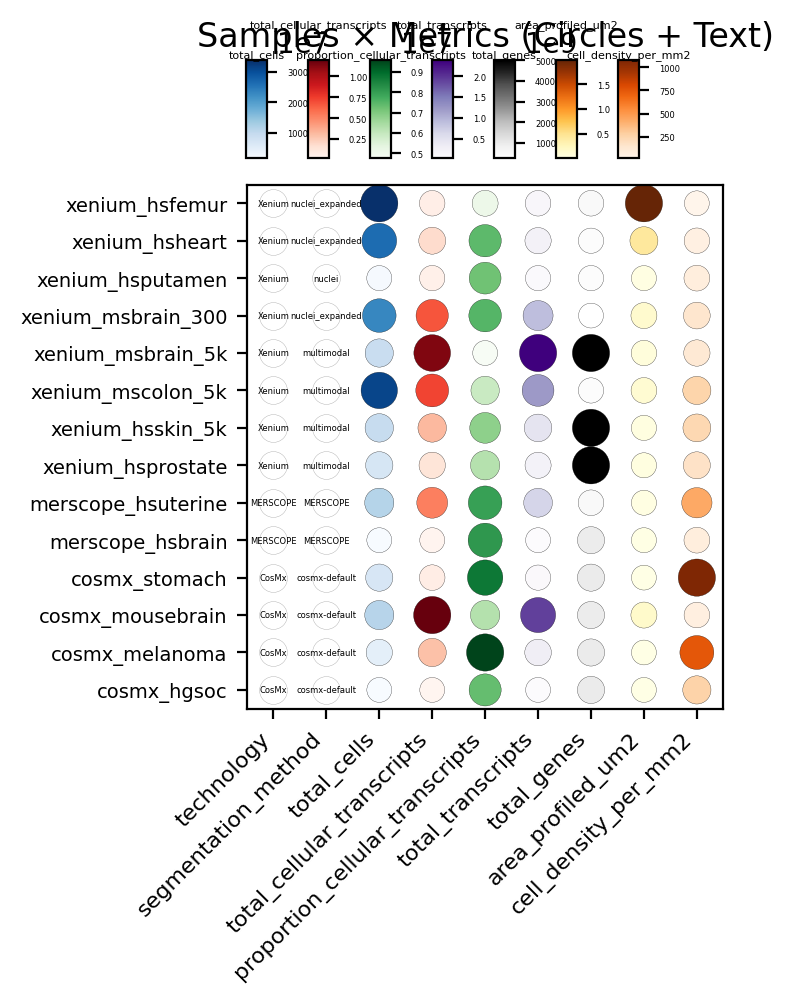

In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from sklearn.preprocessing import MinMaxScaler
from matplotlib import ticker
import matplotlib.pyplot as plt
import matplotlib
import os

# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
# ——————————————————————————————
# 1. Load & Prepare Data
# ——————————————————————————————

# Example: replace with your real CSV path

# Define which fields to show
text_cols = ["technology", "segmentation_method"]  # non-numeric columns
metric_cols = [
    "total_cells",
    "total_cellular_transcripts",
    "proportion_cellular_transcripts",
    "total_transcripts",
    "total_genes",
    "area_profiled_um2",
    "cell_density_per_mm2",
]

markers = ["o", "o", "o", "o", "o", "o", "o", "o", "o"]
all_cols = text_cols + metric_cols

df = combined_metadata[all_cols].copy()
n_samples, n_metrics = df.shape

# Normalize each numeric column to [0,1]
scaler = MinMaxScaler()
df_norm = df.copy()
df_norm[metric_cols] = scaler.fit_transform(df[metric_cols])


# ——————————————————————————————
# 2. Set Up Plot Grid
# ——————————————————————————————

fig, ax = plt.subplots(figsize=(0.40 * n_metrics, max(4, n_samples * 0.35)), dpi=200, constrained_layout=True)

# Scatter grid: one circle per (row, col)
# x positions = column indices, y positions = sample indices
xs = np.repeat(np.arange(n_metrics), n_samples)
ys = np.tile(np.arange(n_samples), n_metrics)

# ——————————————————————————————
# 3. Draw Circles for Text Columns
# ——————————————————————————————

# For text columns, we’ll draw uniform grey circles, then overlay text
for j, col in enumerate(text_cols):
    x = np.full(n_samples, j)
    y = np.arange(n_samples)
    ax.scatter(
        x,
        y,
        s=100,  # circle size
        facecolors="white",
        edgecolors="grey",
        linewidths=0.1,
        zorder=2,
    )
    for yi, txt in enumerate(df[col]):
        ax.text(j, yi, str(txt), ha="center", va="center", fontsize=3, color="k", zorder=3)

# ——————————————————————————————
# 4. Draw Colored Circles for Numeric Metrics
# ——————————————————————————————

# Assign a unique colormap to each metric column
colormaps = [cm.Blues, cm.Reds, cm.Greens, cm.Purples, cm.Greys, cm.YlOrBr,cm.Oranges]

# Plot circles sized & colored by normalized value
for j, col in enumerate(metric_cols, start=len(text_cols)):
    vals = df_norm[col]  # already 0–1 scaled
    cmap = colormaps[j - len(text_cols)]
    colors = cmap(vals)
    mark = markers[j]

    ax.scatter(
        np.full(n_samples, j),  # x pos
        np.arange(n_samples),  # y pos
        s=vals * 100 + 80,  # size roughly proportional
        facecolors=colors,
        edgecolors="k",
        linewidths=0.1,
        zorder=2,
        marker=mark,
    )

# ——————————————————————————————
# 5. Colorbars for Numeric Metrics (Vertical)
# ——————————————————————————————
# ——————————————————————————————
# 5. Colorbars for Numeric Metrics (Vertical above columns)
# ——————————————————————————————
for idx, col in enumerate(metric_cols, start=len(text_cols)):
    cmap = colormaps[idx - len(text_cols)]
    norm = plt.Normalize(vmin=df[col].min(), vmax=df[col].max())
    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])

    # Position: above each metric column (column index = idx)
    col_center = idx  # x position aligned with column
    cbar_width = 0.03
    cbar_height = 0.10  # adjust height
    spacing_above = 0.85  # vertical offset from bottom (near top)

    # Convert data coordinates to figure fraction
    ax_pos = ax.get_position()
    total_width = ax_pos.width
    total_left = ax_pos.x0

    x_frac = total_left + (col_center + 0.5) / n_metrics * total_width
    cax = fig.add_axes([x_frac - cbar_width / 2, spacing_above, cbar_width, cbar_height])

    cbar = plt.colorbar(sm, cax=cax, orientation="vertical")
    cbar.ax.set_title(col, fontsize=4, pad=1)
    cbar.ax.tick_params(labelsize=3)


# ——————————————————————————————
# 6. Final Tuning
# ——————————————————————————————

ax.set_xlim(-0.5, n_metrics - 0.5)
ax.set_ylim(n_samples - 0.5, -0.5)  # flip so first sample is on top

ax.set_xticks(np.arange(n_metrics))
ax.set_xticklabels(all_cols, rotation=45, ha="right", fontsize=8)
ax.set_yticks(np.arange(n_samples))
ax.set_yticklabels(df.index, fontsize=7)

# light grid
ax.set_xticks(np.arange(-0.5, n_metrics, 1), minor=True)
ax.set_yticks(np.arange(-0.5, n_samples, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=1)
ax.tick_params(which="minor", length=0)

ax.set_title("Samples × Metrics (Circles + Text)", fontsize=12, pad=50)

plt.savefig(os.path.join(saving_path, 'metadata_info_per_sample.pdf'))
plt.show()

